# Trabajo Práctico N° 2: árboles de decisión, Bayes Ingenuo y k-NN

- Año: 2026
- Materia: Minería de Datos
- Integrantes: Frank, Maximiliano; Winter, [completar nombre y apellido]

Referencias: U2, U4 y U5 son las unidades de la materia. En las citas, "p." indica la página de la presentación y "c." la celda del notebook de clase (Reg: U4 regresión, ADC: U4 clasificación, KNN y NB: U5). Todas las particiones y todos los modelos usan random_state=63.

In [1]:
# Librerías y semilla
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, KBinsDiscretizer
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import (mean_absolute_error, mean_squared_error, accuracy_score,
                             precision_score, recall_score, ConfusionMatrixDisplay)

SEED = 63  # random_state de todas las particiones y modelos


# Adaptado de U2_Reducción_de_la_dimensionalidad.ipynb, celda 15
def plot_correlation_heatmap(corr, title):
    ax = sns.heatmap(corr, vmin=-1, vmax=1, center=0,
                     cmap=sns.diverging_palette(20, 220, n=200),
                     square=True, annot=True, annot_kws={'size': 8})
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, horizontalalignment='right')
    plt.title(title)
    plt.show()


# Adaptado de U4_DesicionTreeClassifier.ipynb, celda 3 (métricas) y U4 p.51 (average='macro')
def metricas(y, pred):
    return {"Precision macro": precision_score(y, pred, average="macro", zero_division=0),
            "Recall macro": recall_score(y, pred, average="macro", zero_division=0),
            "Accuracy": accuracy_score(y, pred)}


def plot_cms(items, titulo):
    """items: lista de (y_real, y_pred, título). Una matriz de confusión por panel."""
    fig, axes = plt.subplots(1, len(items), figsize=(5.5 * len(items), 4.8))
    for ax, (y, p, t) in zip(np.atleast_1d(axes), items):
        ConfusionMatrixDisplay.from_predictions(y, p, ax=ax, cmap="Blues", colorbar=False)
        ax.set_title(t)
    plt.suptitle(titulo)
    plt.tight_layout()
    plt.show()

# Parte A: regresión (1000_Companies.csv)

## Actividad 1. Preparación de datos

Consigna: hacer el EDA (distribuciones, faltantes, correlaciones), limpiar el conjunto, codificar las categóricas, estandarizar las numéricas y generar las particiones 80/20 y 70/30 con random_state=63.

Seguimos el orden de la consigna: EDA sobre el conjunto completo, limpieza y partición. Los codificadores y el estandarizador se ajustan solo con train, para evitar fuga de datos (U4 p.70). Empezamos por la estructura, los nulos, los duplicados y las categorías.

In [2]:
# Adaptado de U2, celdas 18-24 (estructura y descriptivas)
df = pd.read_csv("1000_Companies.csv")
display(df.head())
df.info()

,RyD_Spend,Administration,MarketingSpend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   RyD_Spend       1000 non-null   float64
 1   Administration  1000 non-null   float64
 2   MarketingSpend  1000 non-null   float64
 3   State           1000 non-null   str    
 4   Profit          1000 non-null   float64
dtypes: float64(4), str(1)
memory usage: 39.2 KB


In [3]:
# Adaptado de U2, celdas 35 y 60 (categóricas y nulos)
print("Columnas con nulos:", df.isna().any().sum())
print("Filas duplicadas:", df.duplicated().sum())
display(df[df.duplicated(keep=False)])
print("\nCeros por columna numérica:")
print((df.select_dtypes("number") == 0).sum().to_string())
print("\nState:")
print(df["State"].value_counts().to_string())
df.describe()

Columnas con nulos: 0
Filas duplicadas: 1


,RyD_Spend,Administration,MarketingSpend,State,Profit
335,84533.0,122941.3141,231885.6935,California,121248.7116
755,84533.0,122941.3141,231885.6935,California,121248.7116



Ceros por columna numérica:
RyD_Spend         2
Administration    0
MarketingSpend    3
Profit            0

State:
State
California    344
New York      334
Florida       322


,RyD_Spend,Administration,MarketingSpend,Profit
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,81668.927200,122963.897612,226205.058419,119546.164656
std,46537.567891,12613.927535,91578.393542,42888.633848
min,0.000000,51283.140000,0.000000,14681.400000
25%,43084.500000,116640.684850,150969.584600,85943.198543
50%,79936.000000,122421.612150,224517.887350,117641.466300
75%,124565.500000,129139.118000,308189.808525,155577.107425
max,165349.200000,321652.140000,471784.100000,476485.430000


Resultado de la inspección: el conjunto tiene 1000 filas y 5 columnas, sin valores faltantes. Hay una fila duplicada (filas 335 y 755). State tiene tres categorías parejas (California 344, New York 334, Florida 322). RyD_Spend tiene 2 ceros y MarketingSpend tiene 3. El máximo de Profit (476485) está muy lejos de su mediana (117641).

Hipótesis previa: esperamos que Profit crezca con RyD_Spend y con MarketingSpend, que Administration tenga una relación débil con Profit y que State influya poco. Esperamos también que RyD_Spend y MarketingSpend estén correlacionadas entre sí. Los gráficos siguientes ponen a prueba esta hipótesis.

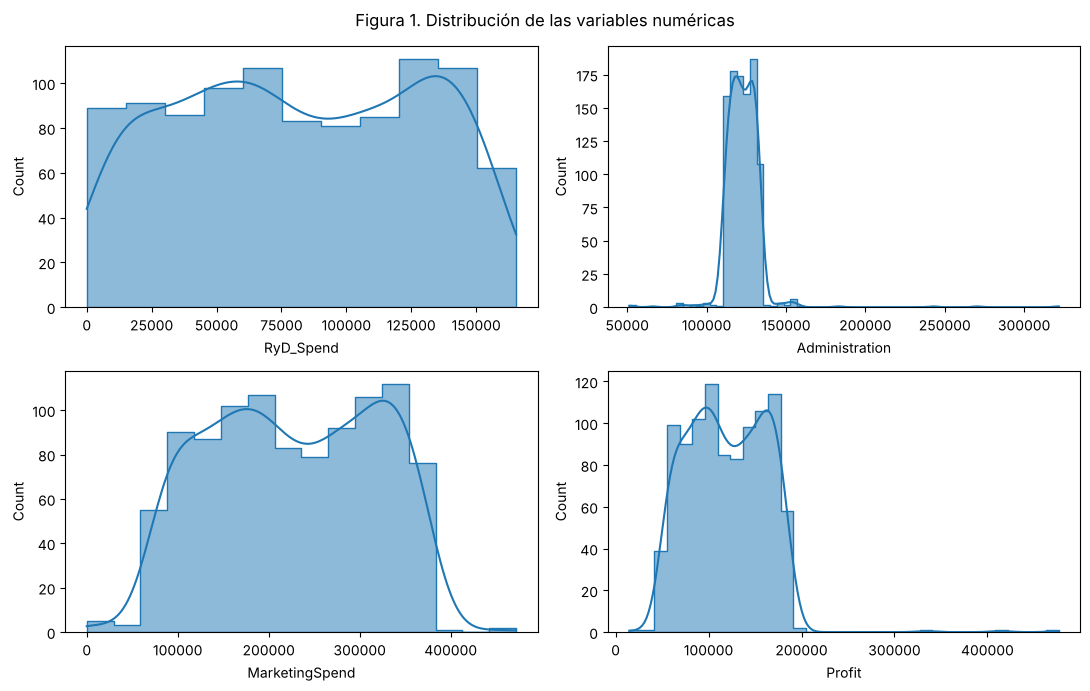

In [4]:
# Adaptado de U4_DecisionTreeRegresion.ipynb, celda 22 (histogramas)
num_cols = ["RyD_Spend", "Administration", "MarketingSpend", "Profit"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for col, ax in zip(num_cols, axes.flatten()):
    sns.histplot(data=df, x=col, kde=True, element="step", ax=ax)
plt.suptitle("Figura 1. Distribución de las variables numéricas")
plt.tight_layout()
plt.show()

Figura 1. RyD_Spend va de 0 a 165349 y MarketingSpend de 0 a 471784, con la mayoría de sus valores entre unos 60000 y 400000. Administration se concentra entre 100000 y 150000 y tiene valores aislados hasta 321652. Profit se concentra entre unos 40000 y 190000 y tiene una cola hasta 476485. La cola de Profit y los valores aislados de Administration son candidatos a atípicos. La figura describe cada variable por separado y no permite probar la hipótesis, que trata de relaciones entre variables.

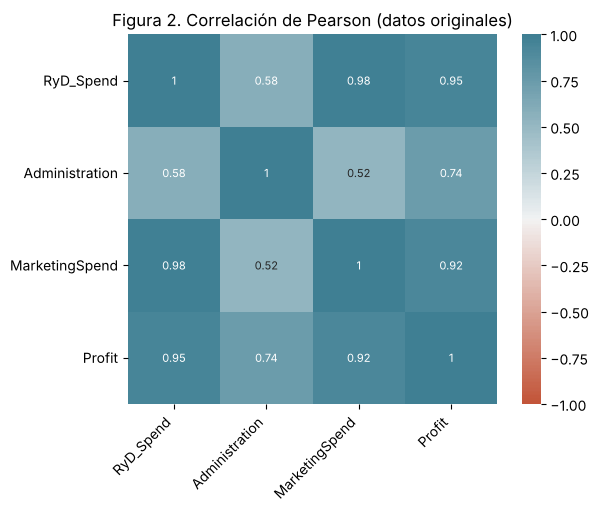

Spearman con Profit:
RyD_Spend         0.998
Administration    0.932
MarketingSpend    0.982
Profit            1.000


In [5]:
# Correlación: heatmap de U2, celda 15
plot_correlation_heatmap(df[num_cols].corr(), "Figura 2. Correlación de Pearson (datos originales)")
print("Spearman con Profit:")
print(df[num_cols].corr(method="spearman")["Profit"].round(3).to_string())

Figura 2. Profit tiene correlación de Pearson de 0.95 con RyD_Spend, 0.92 con MarketingSpend y 0.74 con Administration. RyD_Spend y MarketingSpend tienen 0.98 entre sí. Con Spearman, Profit queda en 0.998, 0.982 y 0.932 respectivamente. Spearman da valores más altos que Pearson en las tres variables, lo que sugiere que los valores extremos de Profit reducen el Pearson.

La hipótesis se cumple para RyD_Spend y MarketingSpend, y para la correlación entre ambas. No se cumple para Administration: su correlación es moderada y no débil. Como RyD_Spend y MarketingSpend aportan información casi igual, esperamos que el árbol use una de las dos en los primeros cortes.

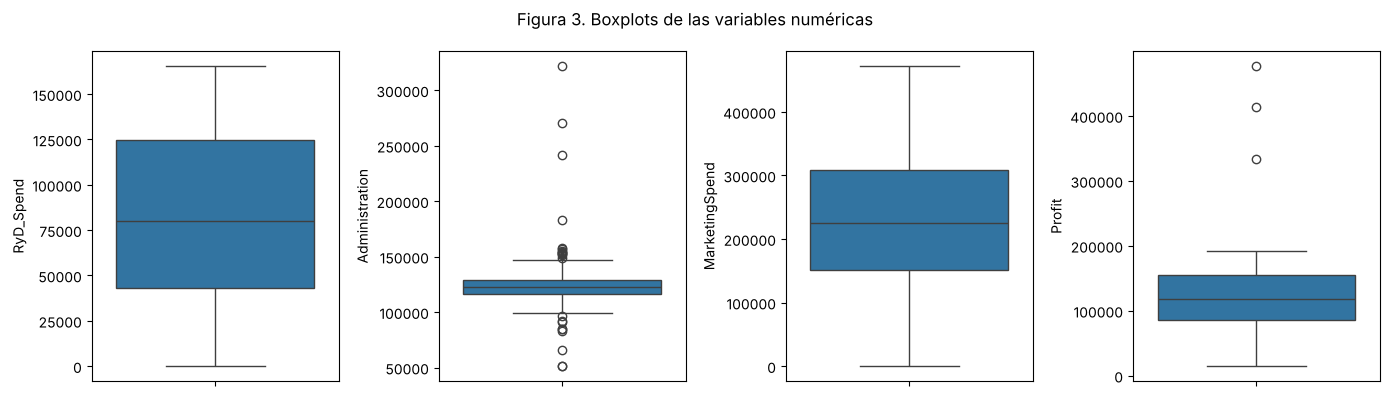

RyD_Spend: 0 atípicos (0.0%), límites [-79137, 246787]
Administration: 22 atípicos (2.2%), límites [97893, 147887]
MarketingSpend: 0 atípicos (0.0%), límites [-84861, 544020]
Profit: 3 atípicos (0.3%), límites [-18508, 260028]


In [6]:
# Adaptado de U4_DecisionTreeRegresion.ipynb, celdas 47-48 y U2, celdas 48 y 50 (boxplot y conteo IQR)
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for col, ax in zip(num_cols, axes):
    sns.boxplot(y=df[col], ax=ax)
plt.suptitle("Figura 3. Boxplots de las variables numéricas")
plt.tight_layout()
plt.show()

for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, up = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((df[col] < low) | (df[col] > up)).sum()
    print(f"{col}: {n} atípicos ({n / len(df) * 100:.1f}%), límites [{low:.0f}, {up:.0f}]")

Figura 3. El conteo por IQR da 0 atípicos en RyD_Spend, 0 en MarketingSpend, 22 en Administration (2.2%) y 3 en Profit (0.3%). Siguiendo U2 c51 a c57, antes de borrar revisamos si esas filas siguen el comportamiento del resto de los datos.

,RyD_Spend,Administration,MarketingSpend,State,Profit
997,100275.47,241926.31,227142.82,California,413956.48
998,128456.23,321652.14,281692.32,California,333962.19
999,161181.72,270939.86,295442.17,New York,476485.43


Atípicos de Administration fuera de las 3 filas anómalas: 19, índice máximo 48
Profit de esas filas: 35673.0 a 191792.0


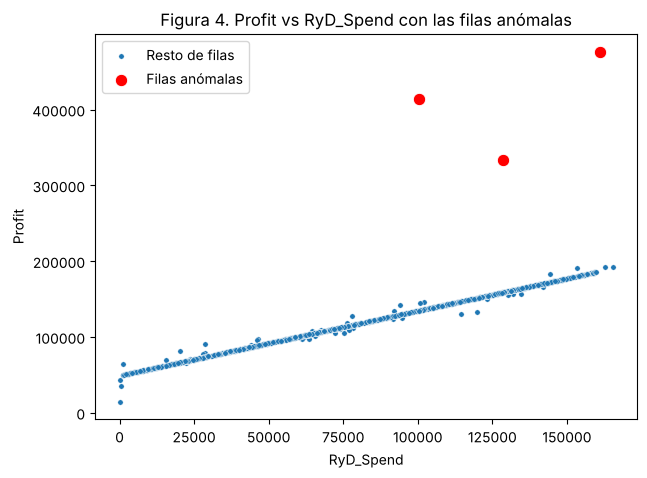

In [7]:
# Filas con Profit fuera del límite IQR (criterio de U2, celda 50)
q1, q3 = df["Profit"].quantile([0.25, 0.75])
anomalas = df[(df["Profit"] > q3 + 1.5 * (q3 - q1)) | (df["Profit"] < q1 - 1.5 * (q3 - q1))]
display(anomalas)

# Atípicos de Administration (U2, celdas 51-57: revisar si pertenecen al comportamiento del resto antes de borrar)
qa1, qa3 = df["Administration"].quantile([0.25, 0.75])
adm = df[((df["Administration"] > qa3 + 1.5 * (qa3 - qa1)) | (df["Administration"] < qa1 - 1.5 * (qa3 - qa1)))
         & ~df.index.isin(anomalas.index)]
print(f"Atípicos de Administration fuera de las 3 filas anómalas: {len(adm)}, índice máximo {adm.index.max()}")
print("Profit de esas filas:", adm["Profit"].min().round(0), "a", adm["Profit"].max().round(0))

# Comparación original vs limpio (idea de U2, celdas 54-55)
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=df, x="RyD_Spend", y="Profit", s=15, ax=ax, label="Resto de filas")
sns.scatterplot(data=anomalas, x="RyD_Spend", y="Profit", color="red", s=80, ax=ax, label="Filas anómalas")
plt.title("Figura 4. Profit vs RyD_Spend con las filas anómalas")
plt.show()

Figura 4. Profit sigue una recta casi perfecta con RyD_Spend, como anticipaba la hipótesis. Las tres filas marcadas en rojo (997, 998 y 999) quedan muy por encima de la recta. Tienen Profit de 413956, 333962 y 476485, entre 1.7 y 2.5 veces el máximo del resto (192262), y Administration de 241926, 321652 y 270940, por encima del máximo del resto (182646). Son los únicos atípicos de Profit por IQR.

Los otros 19 atípicos de Administration están entre las primeras 50 filas del archivo (índice máximo 48) y tienen Profit entre 35673 y 191792, dentro del rango del resto. Esas filas siguen la relación con RyD_Spend.

In [8]:
# ⚠️ REVISAR: drop_duplicates() no aparece en el material (solo duplicated(), SVM celda 16)
df_clean = df.drop(index=anomalas.index).drop_duplicates()
print("Filas:", len(df), "->", len(df_clean))
print("Correlación de Pearson con Profit:")
print(pd.DataFrame({"original": df[num_cols].corr()["Profit"], "limpio": df_clean[num_cols].corr()["Profit"]}).round(3))
print("Máximos después de limpiar:")
print(df_clean[num_cols].max().to_string())

Filas: 1000 -> 996
Correlación de Pearson con Profit:
                original  limpio
RyD_Spend          0.945   0.999
Administration     0.742   0.745
MarketingSpend     0.917   0.981
Profit             1.000   1.000
Máximos después de limpiar:
RyD_Spend         165349.20
Administration    182645.56
MarketingSpend    471784.10
Profit            192261.83


Decisiones de limpieza:

- Eliminamos las 3 filas anómalas. No siguen la relación que cumplen las demás filas (Figura 4) y son los únicos atípicos de Profit.
- Conservamos los 19 atípicos restantes de Administration, porque su Profit es coherente con el resto.
- Conservamos los ceros de RyD_Spend y MarketingSpend, que son valores de gasto posibles. No hay nulos para imputar.
- Eliminamos la fila duplicada. Si una copia cae en train y la otra en test, el test incluye un ejemplo ya visto.

El conjunto pasa de 1000 a 996 filas. Después de limpiar, la correlación de Profit con RyD_Spend sube de 0.945 a 0.999 y con MarketingSpend de 0.917 a 0.981. Con Administration casi no cambia (0.742 a 0.745), por lo que su correlación moderada no depende de las tres filas eliminadas. La Actividad 2 muestra el efecto de la limpieza sobre el error.

In [9]:
# Adaptado de U4_DecisionTreeRegresion.ipynb, celda 37 (partición) con random_state=63 y dos proporciones
X = df_clean.drop(columns="Profit")
y = df_clean["Profit"]
particiones = {}
for nombre, ts in [("80/20", 0.2), ("70/30", 0.3)]:
    particiones[nombre] = train_test_split(X, y, test_size=ts, random_state=SEED)
    print(nombre, "-> train:", len(particiones[nombre][0]), "| test:", len(particiones[nombre][1]))

80/20 -> train: 796 | test: 200
70/30 -> train: 697 | test: 299


In [10]:
# Codificación y estandarización con ajuste solo en train (U4 p.70; U5 p.28 para OneHotEncoder)
# ⚠️ REVISAR: OneHotEncoder dentro de make_column_transformer con salida pandas; el material solo lo muestra en teoría (U5 p.28)
num_X = ["RyD_Spend", "Administration", "MarketingSpend"]

def preparar(Xtr, Xte, escalar):
    ct = make_column_transformer(
        (OneHotEncoder(sparse_output=False), ["State"]),
        (StandardScaler() if escalar else "passthrough", num_X),
        verbose_feature_names_out=False).set_output(transform="pandas")
    return ct.fit_transform(Xtr), ct.transform(Xte)

# "orig": variables en unidades originales (para graficar el árbol); "std": estandarizadas
datos = {n: {"orig": preparar(p[0], p[1], False), "std": preparar(p[0], p[1], True)}
         for n, p in particiones.items()}
datos["80/20"]["orig"][0].head()

,State_California,State_Florida,State_New York,RyD_Spend,Administration,MarketingSpend
398,1.0,0.0,0.0,12412.0,112290.1563,92728.02707
794,1.0,0.0,0.0,12564.0,112312.6043,93021.31149
102,0.0,1.0,0.0,127529.0,129291.1592,314846.59290
883,1.0,0.0,0.0,64529.0,119987.0323,193287.92090
219,1.0,0.0,0.0,10758.0,112045.8860,89536.62956


Codificación y estandarización: State se codifica con OneHotEncoder (3 columnas), porque los estados no tienen un orden natural (U5 p.28). Las tres variables numéricas se estandarizan con StandardScaler. Ambos transformadores se ajustan solo con train (U4 p.70).

Particiones con random_state=63: el 80/20 deja 796 filas de train y 200 de test, y el 70/30 deja 697 y 299. Guardamos dos versiones de cada partición, en unidades originales y estandarizada. La Actividad 2 entrena con las dos y compara los resultados. El árbol que graficamos usa las unidades originales, porque así los umbrales se leen directamente.

## Actividad 2. Árboles de decisión para regresión

Consigna: estimar Profit con DecisionTreeRegressor, explorar max_depth, min_samples_leaf y min_samples_split con al menos 3 valores cada uno, justificar el mejor modelo, graficar el árbol y reportar MAE, MSE y RMSE en ambos test.

Partimos de la grilla de clase (Reg c83 a c85): max_depth con 4 valores (3, 5, 10, None), min_samples_split con 3 (2, 5, 10) y min_samples_leaf con 3 (1, 5, 10). Son 36 combinaciones. Elegimos por validación cruzada de 5 folds sobre train (U4 p.40 y p.44), con el MSE como criterio. Así el test no interviene en la elección.

Hipótesis previa: el primer corte será por RyD_Spend, la variable más correlacionada con Profit, y MarketingSpend aparecerá después. Como la relación es casi lineal, esperamos un árbol de profundidad media que la aproxime con escalones.

In [11]:
# Adaptado de U4_DecisionTreeRegresion.ipynb, celdas 83-86 (grilla) y U4_DesicionTreeClassifier.ipynb, celda 33 (GridSearchCV)
# Selección por validación cruzada de 5 folds sobre train (U4 p.40 y p.44), porque el TP solo define train y test
param_grid = {"max_depth": [3, 5, 10, None],
              "min_samples_split": [2, 5, 10],
              "min_samples_leaf": [1, 5, 10]}

grids_A = {}
for nombre, (Xtr, Xte) in {n: d["orig"] for n, d in datos.items()}.items():
    ytr = particiones[nombre][2]
    grids_A[nombre] = GridSearchCV(DecisionTreeRegressor(random_state=SEED), param_grid, cv=5,
                                   scoring="neg_mean_squared_error").fit(Xtr, ytr)
    res = pd.DataFrame(grids_A[nombre].cv_results_)
    res["MSE (CV)"] = -res["mean_test_score"]
    res["RMSE (CV)"] = np.sqrt(res["MSE (CV)"])
    mejor = grids_A[nombre].best_estimator_
    print(f"Partición {nombre}: mejor configuración = {grids_A[nombre].best_params_}, "
          f"profundidad real = {mejor.get_depth()}, hojas = {mejor.get_n_leaves()}, "
          f"configuraciones empatadas en el primer lugar = {(res['rank_test_score'] == 1).sum()} de {len(res)}")
    display(res.sort_values("rank_test_score")[["rank_test_score", "param_max_depth", "param_min_samples_split",
                                                "param_min_samples_leaf", "MSE (CV)", "RMSE (CV)"]].head(6).round(1))
    # mejor RMSE de CV para cada valor de cada hiperparámetro
    display(pd.concat({h: res.groupby("param_" + h, dropna=False)["RMSE (CV)"].min() for h in param_grid})
            .rename("mejor RMSE (CV)").round(0).to_frame())

Partición 80/20: mejor configuración = {'max_depth': 10, 'min_samples_leaf': 5, 'min_samples_split': 2}, profundidad real = 8, hojas = 130, configuraciones empatadas en el primer lugar = 6 de 36


,rank_test_score,param_max_depth,param_min_samples_split,param_min_samples_leaf,MSE (CV),RMSE (CV)
30,1,None,2,5,3899478.2,1974.7
21,1,10,2,5,3899478.2,1974.7
23,1,10,10,5,3899478.2,1974.7
31,1,None,5,5,3899478.2,1974.7
22,1,10,5,5,3899478.2,1974.7
32,1,None,10,5,3899478.2,1974.7


mejor RMSE (CV)
max_depth         3.0            5393.0
                  5.0            2475.0
                  10.0           1975.0
                  NaN            1975.0
min_samples_split 2.0            1975.0
                  5.0            1975.0
                  10.0           1975.0
min_samples_leaf  1.0            2349.0
                  5.0            1975.0
                  10.0           2178.0

Partición 70/30: mejor configuración = {'max_depth': 10, 'min_samples_leaf': 5, 'min_samples_split': 2}, profundidad real = 8, hojas = 106, configuraciones empatadas en el primer lugar = 6 de 36


,rank_test_score,param_max_depth,param_min_samples_split,param_min_samples_leaf,MSE (CV),RMSE (CV)
30,1,None,2,5,5352991.4,2313.7
21,1,10,2,5,5352991.4,2313.7
23,1,10,10,5,5352991.4,2313.7
31,1,None,5,5,5352991.4,2313.7
22,1,10,5,5,5352991.4,2313.7
32,1,None,10,5,5352991.4,2313.7


mejor RMSE (CV)
max_depth         3.0            5546.0
                  5.0            2574.0
                  10.0           2314.0
                  NaN            2314.0
min_samples_split 2.0            2314.0
                  5.0            2314.0
                  10.0           2314.0
min_samples_leaf  1.0            2993.0
                  5.0            2314.0
                  10.0           2442.0

En las dos particiones gana la misma configuración: max_depth=10, min_samples_leaf=5 y min_samples_split=2. Su RMSE de validación es 1974.7 en la partición 80/20 y 2313.7 en la 70/30. Hay 6 configuraciones empatadas en el primer lugar en cada partición, y GridSearchCV devuelve la primera. El empate tiene dos causas:

- El árbol con max_depth=10 llega solo a profundidad 8, por lo que max_depth=None produce el mismo árbol.
- Con min_samples_leaf=5, un nodo necesita al menos 10 observaciones para dividirse. Por eso min_samples_split=2, 5 y 10 producen el mismo árbol.

Efecto de cada hiperparámetro sobre el mejor RMSE de validación (80/20 y 70/30):

- max_depth: 3 da 5393 y 5546, 5 da 2475 y 2574, y 10 o None dan 1975 y 2314. Con poca profundidad el árbol queda en subajuste y no alcanza a seguir la relación (U4 p.10).
- min_samples_leaf: 1 da 2349 y 2993, 5 da 1975 y 2314, y 10 da 2178 y 2442. Con hojas de una observación el árbol se ajusta al ruido (U4 p.11). Con hojas de 10 pierde detalle. El valor 5 queda en el punto de equilibrio entre sesgo y varianza (U4 p.12).
- min_samples_split no modifica el resultado.

Elegimos max_depth=10, min_samples_leaf=5 y min_samples_split=2. El árbol resultante tiene profundidad 8 y 130 hojas en el 80/20, y 106 hojas en el 70/30.

In [12]:
# Adaptado de U4_DecisionTreeRegresion.ipynb, celda 79 (MAE, MSE, RMSE) sobre ambos conjuntos de test
filas = []
preds_A = {}
for nombre, g in grids_A.items():
    Xte, yte = datos[nombre]["orig"][1], particiones[nombre][3]
    preds_A[nombre] = g.best_estimator_.predict(Xte)
    mse = mean_squared_error(yte, preds_A[nombre])
    filas.append({"Partición": nombre, "MAE": mean_absolute_error(yte, preds_A[nombre]),
                  "MSE": mse, "RMSE": np.sqrt(mse)})
tabla_A = pd.DataFrame(filas).set_index("Partición")
display(tabla_A.round(1))

# Concentración del error: las 3 filas con mayor error absoluto
for nombre in preds_A:
    err = particiones[nombre][3] - preds_A[nombre]
    top = err.abs().nlargest(3)
    print(f"{nombre}: mayores errores absolutos (fila: error) = {top.round(0).to_dict()}, "
          f"aportan {(top ** 2).sum() / (err ** 2).sum() * 100:.0f}% del error cuadrático total")

# Comprobación (U4_DesicionTreeClassifier.ipynb, celda 23): el árbol no cambia con datos estandarizados
for nombre, g in grids_A.items():
    Xtr_s, Xte_s = datos[nombre]["std"]
    t = DecisionTreeRegressor(random_state=SEED, **g.best_params_).fit(Xtr_s, particiones[nombre][2])
    print(nombre, "RMSE con datos estandarizados:", round(np.sqrt(mean_squared_error(particiones[nombre][3], t.predict(Xte_s))), 1))

,MAE,MSE,RMSE
Partición,,,
80/20,1098.9,12222722.2,3496.1
70/30,942.6,8579615.4,2929.1


80/20: mayores errores absolutos (fila: error) = {45: 26306.0, 38: 24142.0, 14: 20024.0}, aportan 69% del error cuadrático total
70/30: mayores errores absolutos (fila: error) = {45: 26306.0, 38: 24171.0, 14: 20308.0}, aportan 66% del error cuadrático total
80/20 RMSE con datos estandarizados: 3496.1
70/30 RMSE con datos estandarizados: 2929.1


In [13]:
# Efecto de no limpiar (idea de U2, celdas 54-55: resultados antes y después de limpiar)
for nombre, ts in [("80/20", 0.2), ("70/30", 0.3)]:
    Xtr, Xte, ytr, yte = train_test_split(df.drop(columns="Profit"), df["Profit"], test_size=ts, random_state=SEED)
    Xtr, Xte = preparar(Xtr, Xte, False)
    t = DecisionTreeRegressor(random_state=SEED, **grids_A[nombre].best_params_).fit(Xtr, ytr)
    print(f"{nombre}: filas anómalas en test = {yte.index.isin(anomalas.index).sum()}, "
          f"RMSE sin limpiar = {np.sqrt(mean_squared_error(yte, t.predict(Xte))):.1f}, "
          f"RMSE con datos limpios = {tabla_A.loc[nombre, 'RMSE']:.1f}")

80/20: filas anómalas en test = 1, RMSE sin limpiar = 19313.7, RMSE con datos limpios = 3496.1
70/30: filas anómalas en test = 1, RMSE sin limpiar = 15805.7, RMSE con datos limpios = 2929.1


Resultados sobre test (U4 p.66 a p.69):

- Partición 80/20: MAE 1098.9, MSE 12222722.2 y RMSE 3496.1.
- Partición 70/30: MAE 942.6, MSE 8579615.4 y RMSE 2929.1.

El MAE equivale a alrededor del 1% de una mediana de Profit de 117641. El RMSE es mucho mayor que el MAE (3496.1 contra 1098.9), lo que indica pocos errores grandes. El cálculo lo confirma: tres filas del test (45, 38 y 14) aportan el 69% del error cuadrático total en el 80/20 y el 66% en el 70/30, con errores de entre 20000 y 26000. Las tres están entre las primeras 50 filas del archivo, donde la Figura 4 muestra puntos fuera de la recta.

El RMSE del 70/30 es menor que el del 80/20 aunque entrena con menos datos. Las mismas tres filas caen en ambos test, y en el 70/30 su error se reparte entre 299 filas en lugar de 200. La diferencia refleja la composición del test.

Efecto de la limpieza: con la misma configuración, sin eliminar las tres filas anómalas ni el duplicado, el RMSE sube a 19313.7 en el 80/20 y a 15805.7 en el 70/30, contra 3496.1 y 2929.1 con datos limpios. En cada test cae una fila anómala. La comparación es aproximada, porque los dos test no contienen exactamente las mismas filas. El RMSE se multiplica por más de cinco, lo que respalda la decisión de eliminarlas.

Con datos estandarizados el RMSE es idéntico (3496.1 y 2929.1), por lo que la estandarización no cambia el árbol (ADC c23).

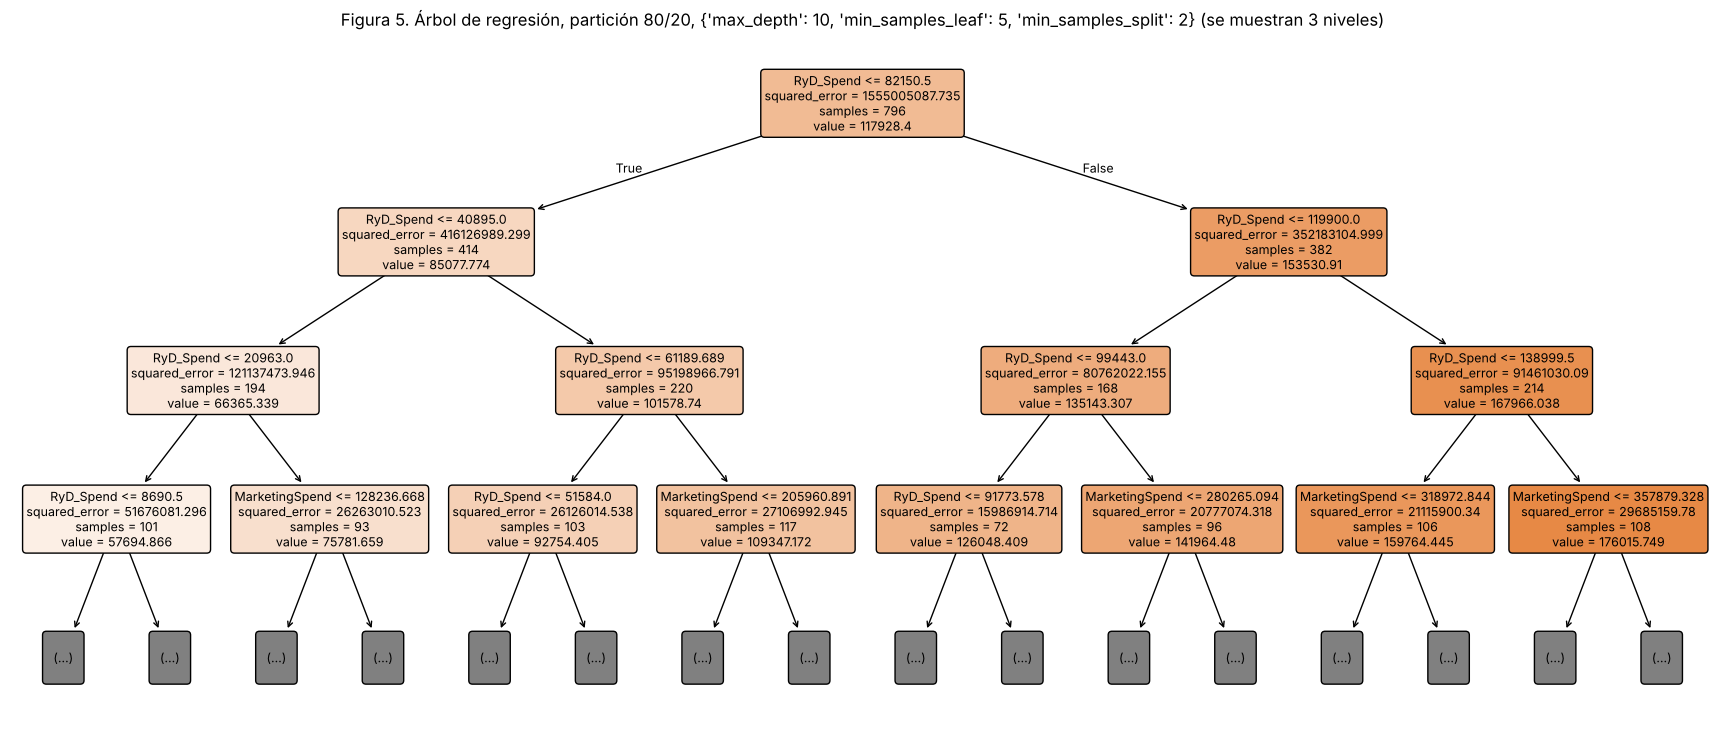

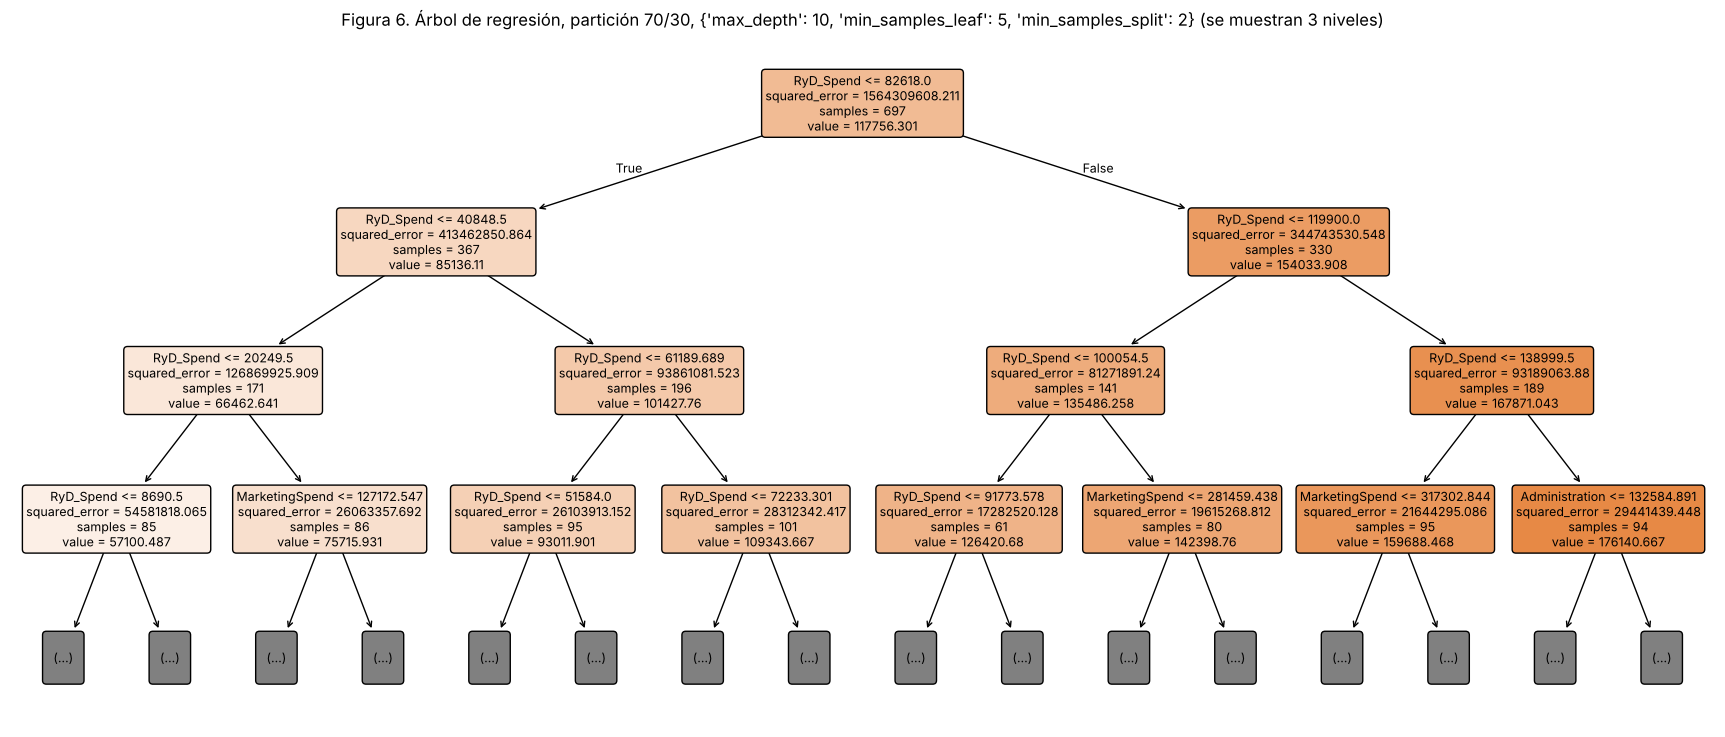

In [14]:
# Adaptado de U4_DecisionTreeRegresion.ipynb, celda 93 (plot_tree con max_depth=3 para que se lea)
for i, (nombre, g) in enumerate(grids_A.items(), 1):
    plt.figure(figsize=(22, 9))
    plot_tree(g.best_estimator_, feature_names=list(datos[nombre]["orig"][0].columns),
              filled=True, rounded=True, max_depth=3, fontsize=9)
    plt.title(f"Figura {4 + i}. Árbol de regresión, partición {nombre}, {g.best_params_} (se muestran 3 niveles)")
    plt.show()

Figuras 5 y 6. Graficamos cada árbol hasta max_depth=3, porque los árboles completos tienen 130 y 106 hojas y no se leen (Reg c93 también limita max_depth). La raíz divide por RyD_Spend (82150.5 en el 80/20 y 82618 en el 70/30). El valor medio de Profit pasa de 85078 en la rama izquierda a 153531 en la derecha del 80/20. La raíz y los dos niveles siguientes dividen siempre por RyD_Spend. En el cuarto nivel de nodos aparece MarketingSpend en ambos árboles, y Administration en un nodo del 70/30. State no aparece en los niveles mostrados.

Esto es coherente con la hipótesis. RyD_Spend es la variable más correlacionada con Profit (0.999 después de limpiar) y MarketingSpend aparece después. Administration, con correlación moderada, casi no interviene.

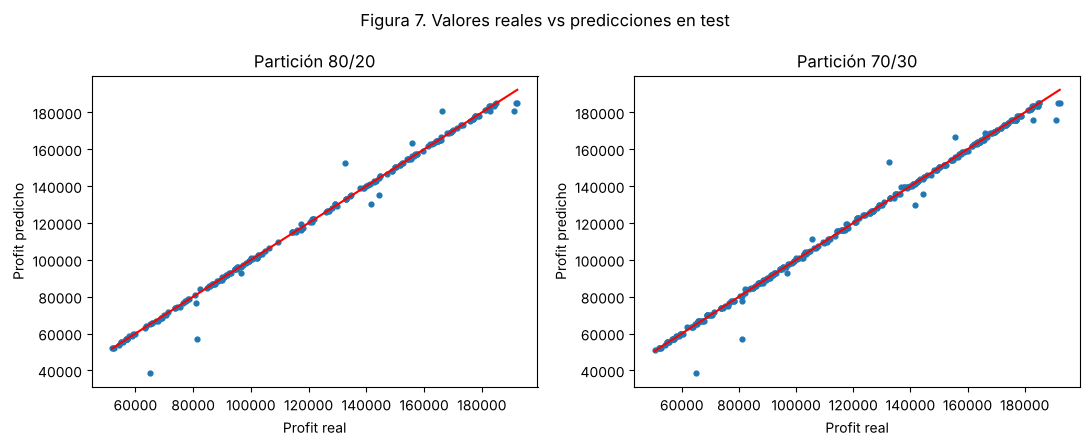

In [15]:
# Adaptado de U4_DecisionTreeRegresion.ipynb, celda 81 (real vs predicción)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, nombre in zip(axes, grids_A):
    yte = particiones[nombre][3]
    ax.scatter(yte, preds_A[nombre], s=12)
    ax.plot([yte.min(), yte.max()], [yte.min(), yte.max()], color="red")
    ax.set_title(f"Partición {nombre}")
    ax.set_xlabel("Profit real")
    ax.set_ylabel("Profit predicho")
plt.suptitle("Figura 7. Valores reales vs predicciones en test")
plt.tight_layout()
plt.show()

Figura 7. En ambos test los puntos se alinean sobre la diagonal. Se separan de ella unos pocos puntos, que son los que concentran el error cuadrático (por ejemplo, el de Profit real cercano a 65000 con predicción cercana a 39000). El gráfico es coherente con la hipótesis de una relación casi lineal y con un MAE bajo. A la escala del gráfico no se distinguen los escalones del árbol.

# Parte B: clasificación (drugType.csv)

## Actividad 3. Preparación de datos

Consigna: hacer el EDA (distribuciones, faltantes, correlaciones y balance de la variable objetivo Droga), limpiar, codificar, estandarizar y generar las particiones 80/20 y 70/30 con random_state=63 y estratificación por Droga.

Usamos el mismo orden que en la Parte A: EDA sobre todo el conjunto y ajuste de transformadores solo con train.

Hipótesis previa: esperamos que Na_a_K sea la variable que mejor separa las clases, que BP y Colesterol aporten reglas adicionales y que Sexo no influya. Esperamos también que las clases no estén parejas.

In [16]:
# Adaptado de U2, celdas 18-24, 35 y 60
dd = pd.read_csv("drugType.csv")
display(dd.head())
dd.info()
print("Columnas con nulos:", dd.isna().any().sum())
print("Filas duplicadas:", dd.duplicated().sum())
for col in ["Sexo", "BP", "Colesterol", "Droga"]:
    print(f"\n{col}:", dd[col].value_counts().sort_index().to_dict())
dd.describe()

,Edad,Sexo,BP,Colesterol,Na_a_K,Droga
0,23,F,Alto,Alto,25.355,DrogaY
1,47,M,Bajo,Alto,13.093,DrogaC
2,47,M,Bajo,Alto,10.114,DrogaC
3,28,F,Normal,Alto,7.798,DrogaX
4,61,F,Bajo,Alto,18.043,DrogaY


<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Edad        200 non-null    int64  
 1   Sexo        200 non-null    str    
 2   BP          200 non-null    str    
 3   Colesterol  200 non-null    str    
 4   Na_a_K      200 non-null    float64
 5   Droga       200 non-null    str    
dtypes: float64(1), int64(1), str(4)
memory usage: 9.5 KB
Columnas con nulos: 0
Filas duplicadas: 0

Sexo: {'F': 96, 'M': 104}

BP: {'Alto': 77, 'Bajo': 64, 'Normal': 59}

Colesterol: {'Alto': 103, 'Normal': 97}

Droga: {'DrogaA': 23, 'DrogaB': 16, 'DrogaC': 16, 'DrogaX': 54, 'DrogaY': 91}


,Edad,Na_a_K
count,200.000000,200.000000
mean,44.315000,16.084485
std,16.544315,7.223956
min,15.000000,6.269000
25%,31.000000,10.445500
50%,45.000000,13.936500
75%,58.000000,19.380000
max,74.000000,38.247000


,Cantidad,Porcentaje
Droga,,
DrogaY,91,45.5
DrogaX,54,27.0
DrogaA,23,11.5
DrogaC,16,8.0
DrogaB,16,8.0


Razón clase mayoritaria / minoritaria: 5.69


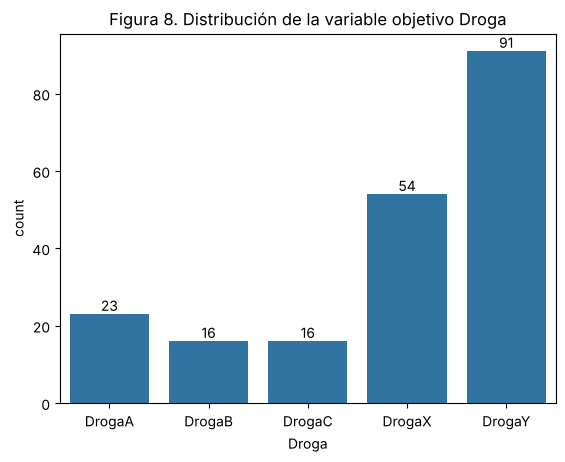

In [17]:
# Adaptado de U4_DesicionTreeClassifier.ipynb, celdas 3 y 10 (balance de clases)
cantidad = dd["Droga"].value_counts()
balance = pd.DataFrame({"Cantidad": cantidad, "Porcentaje": (cantidad / len(dd) * 100).round(1)})
display(balance)
print("Razón clase mayoritaria / minoritaria:", round(cantidad.max() / cantidad.min(), 2))

orden = sorted(dd["Droga"].unique())
ax = sns.countplot(data=dd, x="Droga", order=orden)
ax.bar_label(ax.containers[0])
plt.title("Figura 8. Distribución de la variable objetivo Droga")
plt.show()

Inspección: 200 filas y 6 columnas, sin nulos ni duplicados. Edad va de 15 a 74 y Na_a_K de 6.27 a 38.25. Sexo tiene F 96 y M 104. BP tiene Alto 77, Bajo 64 y Normal 59. Colesterol tiene Alto 103 y Normal 97.

Figura 8. Las clases están desbalanceadas: DrogaY tiene 91 casos (45.5%), DrogaX 54 (27.0%), DrogaA 23 (11.5%), DrogaB 16 (8.0%) y DrogaC 16 (8.0%). La clase mayoritaria es 5.69 veces la minoritaria. Un modelo que responda siempre DrogaY tendría Accuracy de 0.455 (91 de 200). La hipótesis se cumple.

Decisiones: estratificamos las particiones, como pide la consigna, y evaluamos con Precision y Recall macro, que dan el mismo peso a cada clase (U4 p.51), junto con Accuracy. Para elegir hiperparámetros por validación cruzada usamos F1 macro, que combina ambas métricas macro.

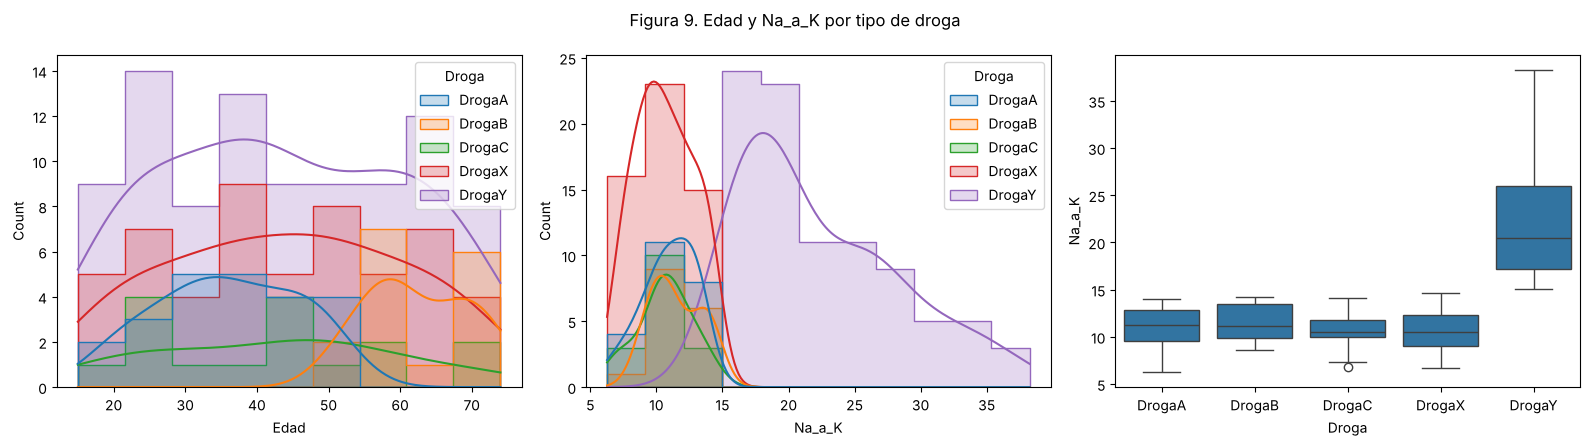

       Edad     Na_a_K       
        min max    min    max
Droga                        
DrogaA   19  50   6.27  13.97
DrogaB   51  74   8.62  14.24
DrogaC   16  72   6.77  14.16
DrogaX   15  74   6.68  14.64
DrogaY   15  74  15.02  38.25 

Droga   DrogaA  DrogaB  DrogaC  DrogaX  DrogaY
BP                                            
Alto        23      16       0       0      38
Bajo         0       0      16      18      30
Normal       0       0       0      36      23 

Droga       DrogaA  DrogaB  DrogaC  DrogaX  DrogaY
Colesterol                                        
Alto            12       8      16      20      47
Normal          11       8       0      34      44 

Droga  DrogaA  DrogaB  DrogaC  DrogaX  DrogaY
Sexo                                         
F           9       6       7      27      47
M          14      10       9      27      44


In [18]:
# Adaptado de U4_DesicionTreeClassifier.ipynb, celda 13 y U2, celda 32 (distribuciones por clase)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.histplot(data=dd, x="Edad", hue="Droga", hue_order=orden, kde=True, element="step", ax=axes[0])
sns.histplot(data=dd, x="Na_a_K", hue="Droga", hue_order=orden, kde=True, element="step", ax=axes[1])
sns.boxplot(data=dd, x="Droga", y="Na_a_K", order=orden, ax=axes[2])
plt.suptitle("Figura 9. Edad y Na_a_K por tipo de droga")
plt.tight_layout()
plt.show()

print(dd.groupby("Droga")[["Edad", "Na_a_K"]].agg(["min", "max"]).round(2), "\n")
print(pd.crosstab(dd["BP"], dd["Droga"]), "\n")
print(pd.crosstab(dd["Colesterol"], dd["Droga"]), "\n")
print(pd.crosstab(dd["Sexo"], dd["Droga"]))

Figura 9 y tablas. Na_a_K separa a DrogaY: sus valores van de 15.02 a 38.25, y los de las otras cuatro clases no superan 14.64. Edad separa a DrogaB (51 a 74 años) de DrogaA (19 a 50). Las demás clases cubren casi todo el rango de edad.

Las tablas de contingencia muestran reglas por categoría. DrogaA y DrogaB aparecen solo con BP Alto (23 y 16 casos). DrogaC aparece solo con BP Bajo (16 casos) y solo con Colesterol Alto. DrogaX aparece con BP Bajo y Normal (18 y 36) y nunca con BP Alto. Sexo reparte cada clase de forma pareja (DrogaX tiene 27 y 27).

La hipótesis se cumple: Na_a_K es la variable principal, BP y Colesterol aportan reglas y Sexo no influye. Edad, que no habíamos previsto, ayuda a distinguir DrogaA de DrogaB.

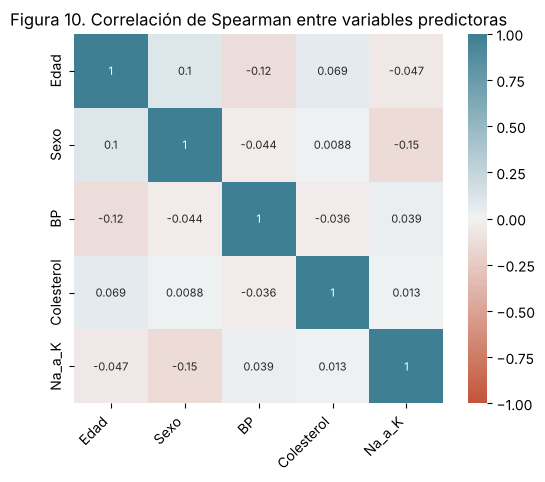

In [19]:
# Correlación Spearman (U4_DesicionTreeClassifier.ipynb, celdas 20-21) con variables ordinales codificadas
cat_cols = ["Sexo", "BP", "Colesterol"]
categorias = [["F", "M"], ["Bajo", "Normal", "Alto"], ["Normal", "Alto"]]  # orden natural de BP y Colesterol
dd_cod = dd.drop(columns="Droga").copy()
dd_cod[cat_cols] = OrdinalEncoder(categories=categorias).fit_transform(dd_cod[cat_cols])
plot_correlation_heatmap(dd_cod.corr(method="spearman"), "Figura 10. Correlación de Spearman entre variables predictoras")

Figura 10. Las correlaciones de Spearman entre predictoras tienen valor absoluto de 0.15 o menos. La mayor es la de Sexo con Na_a_K (-0.15). Las predictoras son casi independientes entre sí, lo que favorece a Bayes Ingenuo, que supone independencia entre atributos (U5 p.2). Tampoco hay redundancia que eliminar para árboles y k-NN. Excluimos Droga de la matriz porque es nominal.

Codificación: Sexo (F, M), BP (Bajo, Normal, Alto) y Colesterol (Normal, Alto) se codifican con OrdinalEncoder y orden natural explícito (KNN c23).

In [20]:
# Adaptado de U2, celdas 50-52: conteo IQR y a qué clase pertenecen los atípicos
for col in ["Edad", "Na_a_K"]:
    q1, q3 = dd[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    mask = (dd[col] < q1 - 1.5 * iqr) | (dd[col] > q3 + 1.5 * iqr)
    print(f"{col}: {mask.sum()} atípicos ({mask.mean() * 100:.1f}%)")
    if mask.sum():
        print("  Clases de los atípicos:", dd.loc[mask, "Droga"].value_counts().to_dict())

Edad: 0 atípicos (0.0%)
Na_a_K: 8 atípicos (4.0%)
  Clases de los atípicos: {'DrogaY': 8}


Atípicos: Edad no tiene ninguno. Na_a_K tiene 8 (4.0%), todos de DrogaY. Siguiendo U2 c51 a c57, revisamos a qué clase pertenecen antes de decidir. Corresponden a los valores altos de DrogaY que muestra la Figura 9. Los conservamos, porque eliminarlos quitaría información de la clase mayoritaria y no hay motivo para considerarlos errores. Como no hay nulos ni duplicados, no hace falta otra limpieza.

In [21]:
# Adaptado de U4_DesicionTreeClassifier.ipynb, celda 16 (partición estratificada) con las dos proporciones del TP
Xd = dd.drop(columns="Droga")
yd = dd["Droga"]
part_B = {}
for nombre, ts in [("80/20", 0.2), ("70/30", 0.3)]:
    part_B[nombre] = train_test_split(Xd, yd, test_size=ts, random_state=SEED, stratify=yd)
conteo = pd.concat({f"{n} {c}": pd.Series(part_B[n][i]).value_counts()
                    for n in part_B for c, i in [("train", 2), ("test", 3)]}, axis=1)
display(conteo)

,80/20 train,80/20 test,70/30 train,70/30 test
Droga,,,,
DrogaY,73,18,64,27
DrogaX,43,11,38,16
DrogaA,18,5,16,7
DrogaC,13,3,11,5
DrogaB,13,3,11,5


In [22]:
# Adaptado de U5_KNNClassifier.ipynb, celdas 23 y 30 (OrdinalEncoder y StandardScaler con fit en train)
def preparar_B(Xtr, Xte, escalar):
    ct = make_column_transformer(
        (OrdinalEncoder(categories=categorias), cat_cols),
        (StandardScaler() if escalar else "passthrough", ["Edad", "Na_a_K"]),
        verbose_feature_names_out=False).set_output(transform="pandas")
    return ct.fit_transform(Xtr), ct.transform(Xte)

datos_B = {n: {"orig": preparar_B(p[0], p[1], False), "std": preparar_B(p[0], p[1], True)}
           for n, p in part_B.items()}
datos_B["80/20"]["std"][0].head()

,Sexo,BP,Colesterol,Edad,Na_a_K
194,0.0,2.0,1.0,0.048965,2.493523
24,0.0,0.0,1.0,-0.734480,2.331313
45,0.0,1.0,0.0,1.254266,-1.099289
114,0.0,1.0,0.0,-1.517926,-0.940594
163,0.0,2.0,0.0,-1.457661,1.675175


Particiones estratificadas: el 80/20 deja 160 filas de train y 40 de test, y el 70/30 deja 140 y 60. Cada clase conserva su proporción. DrogaB, por ejemplo, queda con 13 casos en train y 3 en test (80/20), y con 11 y 5 (70/30). Con 3 a 5 casos de test en las clases chicas, un solo error pesa mucho en el Recall (un error en DrogaB con 3 casos lo baja a 0.67).

Estandarizamos Edad y Na_a_K con StandardScaler ajustado solo con train (U4 p.70, KNN c30). Guardamos una versión original y otra estandarizada. El árbol y el Bayes Ingenuo discretizado usan los datos originales. GaussianNB y k-NN usan los estandarizados.

## Actividad 4. Árboles de decisión para clasificación

Consigna: estimar Droga con DecisionTreeClassifier, explorar max_depth, min_samples_leaf y min_samples_split con al menos 3 valores cada uno, graficar el árbol antes y después de la post-poda con ccp_alpha, justificar el valor elegido y reportar Precision y Recall macro, Accuracy y la matriz de confusión en ambos test.

Partimos de la grilla de clase (ADC c33): max_depth con 5 valores (2, 3, 4, 5, None), min_samples_leaf con 3 (1, 2, 5) y min_samples_split con 3 (2, 5, 10). Son 45 combinaciones, evaluadas con validación cruzada de 5 folds sobre train y F1 macro.

Hipótesis previa: la raíz del árbol usará Na_a_K, y BP y Colesterol aparecerán en las ramas siguientes (Figura 9). Esperamos un árbol chico, porque las clases se separan con pocas reglas.

In [23]:
# Adaptado de U4_DesicionTreeClassifier.ipynb, celda 33 (GridSearchCV) con los 3 hiperparámetros del TP
# ⚠️ REVISAR: scoring="f1_macro" (el notebook usa f1_weighted) y regla de desempate por menor cantidad de hojas
param_grid_B = {"max_depth": [2, 3, 4, 5, None],
                "min_samples_leaf": [1, 2, 5],
                "min_samples_split": [2, 5, 10]}
res_B4 = {}
for nombre, (Xtr, Xte) in {n: d["orig"] for n, d in datos_B.items()}.items():
    ytr, yte = part_B[nombre][2], part_B[nombre][3]
    g = GridSearchCV(DecisionTreeClassifier(random_state=SEED), param_grid_B, cv=5, scoring="f1_macro").fit(Xtr, ytr)
    r = pd.DataFrame(g.cv_results_)
    empatadas = r[r["rank_test_score"] == 1].copy()
    empatadas["hojas"] = empatadas["params"].map(
        lambda p: DecisionTreeClassifier(random_state=SEED, **p).fit(Xtr, ytr).get_n_leaves())
    best = empatadas.sort_values("hojas").iloc[0]
    res_B4[nombre] = {"params": best["params"], "cv": best["mean_test_score"], "n_emp": len(empatadas)}
    print(f"Partición {nombre}: {len(empatadas)} configuraciones empatadas en el primer lugar (de {len(r)}), "
          f"F1 macro CV = {best['mean_test_score']:.3f}")
    print("  Elegida (menos hojas):", best["params"], "| hojas:", best["hojas"])
    # profundidad: menor rendimiento CV en las profundidades bajas
    display(r.groupby("param_max_depth", dropna=False)["mean_test_score"].max().rename("mejor F1 macro CV").round(3).to_frame())

Partición 80/20: 27 configuraciones empatadas en el primer lugar (de 45), F1 macro CV = 0.977
  Elegida (menos hojas): {'max_depth': 4, 'min_samples_leaf': 1, 'min_samples_split': 2} | hojas: 6


,mejor F1 macro CV
param_max_depth,
2.0,0.517
3.0,0.788
4.0,0.977
5.0,0.977
NaN,0.977


Partición 70/30: 27 configuraciones empatadas en el primer lugar (de 45), F1 macro CV = 0.965
  Elegida (menos hojas): {'max_depth': 4, 'min_samples_leaf': 1, 'min_samples_split': 2} | hojas: 6


,mejor F1 macro CV
param_max_depth,
2.0,0.512
3.0,0.761
4.0,0.965
5.0,0.965
NaN,0.965


En cada partición hay 27 configuraciones empatadas en el primer lugar, con F1 macro de validación de 0.977 en el 80/20 y 0.965 en el 70/30. Las profundidades 4, 5 y None alcanzan el mismo valor. La profundidad 2 llega a 0.517 y 0.512, y la 3 a 0.788 y 0.761. El árbol necesita al menos 4 niveles para separar las 5 clases.

Desempatamos por la menor cantidad de hojas, para quedarnos con el árbol más simple y fácil de interpretar (U4 p.2). Resulta max_depth=4, min_samples_leaf=1 y min_samples_split=2 en las dos particiones, con 6 hojas.

In [24]:
# ⚠️ REVISAR: cost_complexity_pruning_path y ccp_alpha no están en el material (U4 p.13 solo explica el concepto)
for nombre, (Xtr, Xte) in {n: d["orig"] for n, d in datos_B.items()}.items():
    ytr = part_B[nombre][2]
    base = DecisionTreeClassifier(random_state=SEED, **res_B4[nombre]["params"])
    alphas = base.cost_complexity_pruning_path(Xtr, ytr).ccp_alphas
    gp = GridSearchCV(base, {"ccp_alpha": alphas}, cv=5, scoring="f1_macro").fit(Xtr, ytr)
    r = pd.DataFrame(gp.cv_results_)
    r["ccp_alpha"] = r["param_ccp_alpha"].astype(float)
    r["hojas"] = [DecisionTreeClassifier(random_state=SEED, **res_B4[nombre]["params"], ccp_alpha=a).fit(Xtr, ytr).get_n_leaves()
                  for a in r["ccp_alpha"]]
    alpha_sel = r.loc[r["rank_test_score"] == 1, "ccp_alpha"].max()   # desempate: el alpha más grande (árbol más simple)
    res_B4[nombre]["alpha"] = alpha_sel
    print(f"Partición {nombre}: ccp_alpha elegido = {alpha_sel:.4f}")
    display(r[["ccp_alpha", "mean_test_score", "hojas"]].rename(columns={"mean_test_score": "F1 macro CV"}).round(4))

Partición 80/20: ccp_alpha elegido = 0.0000


,ccp_alpha,F1 macro CV,hojas
0,0.0000,0.9770,6
1,0.0624,0.8393,4
2,0.0944,0.5957,3
3,0.1442,0.4396,2
4,0.3304,0.2865,1


Partición 70/30: ccp_alpha elegido = 0.0000


,ccp_alpha,F1 macro CV,hojas
0,0.0000,0.9655,6
1,0.0609,0.9184,4
2,0.0931,0.6620,3
3,0.1454,0.4366,2
4,0.3316,0.2429,1


Poda por complejidad. Para cada partición evaluamos con validación cruzada (F1 macro) los valores de ccp_alpha de la secuencia de poda del árbol elegido (U4 p.13). Resultados:

- Partición 80/20: alpha 0 da 0.9770 con 6 hojas. Los siguientes valores dan 0.8393 (4 hojas), 0.5957 (3), 0.4396 (2) y 0.2865 (1).
- Partición 70/30: alpha 0 da 0.9655 con 6 hojas. Los siguientes valores dan 0.9184 (4 hojas), 0.6620 (3), 0.4366 (2) y 0.2429 (1).

Todo alpha mayor que 0 baja el F1 de validación. Elegimos ccp_alpha=0.0 en las dos particiones. La poda no recorta nada, porque la búsqueda de hiperparámetros ya dejó un árbol de 6 hojas, cerca del mínimo para separar 5 clases. Con 4 hojas el árbol no puede predecir las 5 clases. Por eso el árbol antes y después de la poda es el mismo (Figuras 11 y 12).

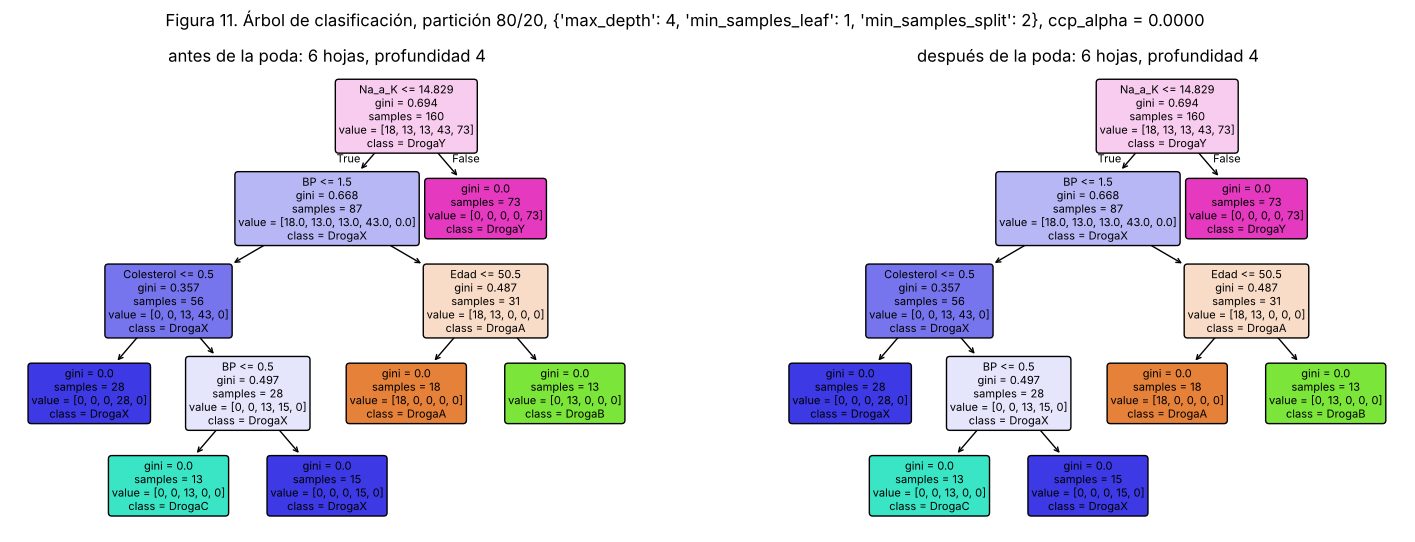

80/20 Accuracy con datos estandarizados: 1.0


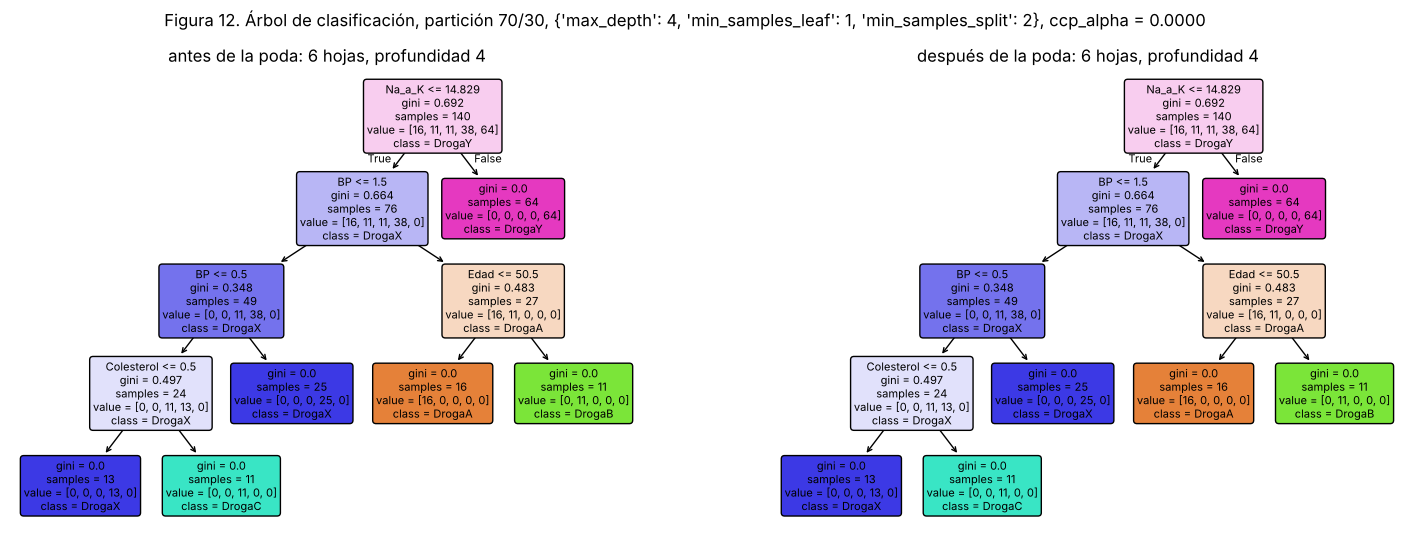

70/30 Accuracy con datos estandarizados: 1.0


,,Precision macro,Recall macro,Accuracy
Modelo,Partición,,,
Árbol antes de podar,80/20,1.0,1.0,1.0
Árbol podado,80/20,1.0,1.0,1.0
Árbol antes de podar,70/30,1.0,1.0,1.0
Árbol podado,70/30,1.0,1.0,1.0


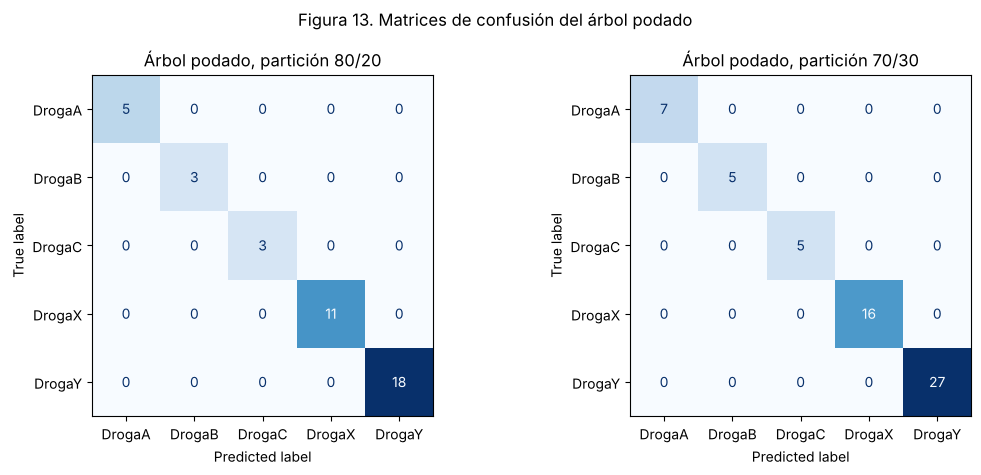

In [25]:
# Árbol antes y después de la post-poda, y métricas sobre ambos test
# Adaptado de U4_DesicionTreeClassifier.ipynb, celdas 29 (plot_tree) y 3 (reporte y matriz de confusión)
met_B = {}      # (modelo, partición) -> métricas
preds_B = {}    # (modelo, partición) -> predicciones
for i, nombre in enumerate(part_B, 1):
    Xtr, Xte = datos_B[nombre]["orig"]
    ytr, yte = part_B[nombre][2], part_B[nombre][3]
    p = res_B4[nombre]["params"]
    antes = DecisionTreeClassifier(random_state=SEED, **p).fit(Xtr, ytr)
    despues = DecisionTreeClassifier(random_state=SEED, **p, ccp_alpha=res_B4[nombre]["alpha"]).fit(Xtr, ytr)
    fig, axes = plt.subplots(1, 2, figsize=(18, 6))
    for ax, t, tit in [(axes[0], antes, "antes de la poda"), (axes[1], despues, "después de la poda")]:
        plot_tree(t, feature_names=list(Xtr.columns), class_names=list(t.classes_), filled=True, rounded=True,
                  fontsize=8, ax=ax)
        ax.set_title(f"{tit}: {t.get_n_leaves()} hojas, profundidad {t.get_depth()}")
    plt.suptitle(f"Figura {10 + i}. Árbol de clasificación, partición {nombre}, {p}, ccp_alpha = {res_B4[nombre]['alpha']:.4f}")
    plt.show()
    for etiqueta, t in [("Árbol antes de podar", antes), ("Árbol podado", despues)]:
        preds_B[(etiqueta, nombre)] = t.predict(Xte)
        met_B[(etiqueta, nombre)] = metricas(yte, preds_B[(etiqueta, nombre)])
    # Comprobación: mismo árbol con datos estandarizados
    Xtr_s, Xte_s = datos_B[nombre]["std"]
    ts_ = DecisionTreeClassifier(random_state=SEED, **p, ccp_alpha=res_B4[nombre]["alpha"]).fit(Xtr_s, ytr)
    print(nombre, "Accuracy con datos estandarizados:", round(accuracy_score(yte, ts_.predict(Xte_s)), 3))

tabla_B4 = pd.DataFrame({k: v for k, v in met_B.items() if k[0].startswith("Árbol")}).T
tabla_B4.index.names = ["Modelo", "Partición"]
display(tabla_B4.round(3))
plot_cms([(part_B[n][3], preds_B[("Árbol podado", n)], f"Árbol podado, partición {n}") for n in part_B],
         "Figura 13. Matrices de confusión del árbol podado")

Figuras 11 y 12. Los dos árboles tienen la raíz en Na_a_K <= 14.829. La rama derecha es pura de DrogaY (73 casos en el 80/20 y 64 en el 70/30). El umbral queda entre el máximo de las otras clases (14.64) y el mínimo de DrogaY (15.02). En la rama izquierda, BP separa los casos. Con BP Alto, Edad <= 50.5 separa a DrogaA de DrogaB. Con BP Bajo o Normal, Colesterol y BP separan a DrogaC de DrogaX, y DrogaC aparece solo con BP Bajo y Colesterol Alto. Las reglas coinciden con las tablas de la Figura 9. La hipótesis se cumple. Edad aparece además como variable para separar DrogaA de DrogaB.

Métricas sobre test: Precision macro, Recall macro y Accuracy valen 1.000 en ambas particiones, antes y después de la poda. La Figura 13 muestra matrices de confusión sin errores (80/20: 5, 3, 3, 11 y 18 casos en la diagonal; 70/30: 7, 5, 5, 16 y 27). Con datos estandarizados el Accuracy también es 1.0, por lo que el árbol no depende de la escala.

Un resultado de 1.0 sobre 40 y 60 observaciones, con 3 a 5 casos en las clases chicas, es evidencia limitada. Lo leemos como que las reglas aprendidas explican este conjunto. Para datos nuevos haría falta más muestra.

## Actividad 5. Bayes Ingenuo

Consigna: estimar Droga con Naive Bayes, discretizando los atributos continuos por equal-frequency con al menos 3 y 5 intervalos y aplicando CategoricalNB o MultinomialNB. Como alternativa se permite GaussianNB sobre los datos continuos. Reportar Precision y Recall macro, Accuracy y la matriz de confusión en ambos test.

Discretizamos Edad y Na_a_K con KBinsDiscretizer por cuantiles, en 3 y en 5 intervalos. Codificamos los intervalos y las categóricas con one-hot (U5 p.28) y aplicamos MultinomialNB (NB c44). Como alternativa usamos GaussianNB sobre los datos estandarizados (NB c36). El discretizador se ajusta solo con train. Elegimos el mejor de los tres modelos por validación cruzada de 5 folds sobre train, sin mirar el test.

Hipótesis previa: con más intervalos se conserva más información de Na_a_K, por lo que 5 intervalos debería rendir mejor que 3. GaussianNB podría rendir peor, porque Na_a_K de DrogaY es asimétrica (Figura 9).

In [26]:
# Adaptado de U5_BayesClassifier.ipynb, celdas 36 (GaussianNB) y 44 (MultinomialNB)
# ⚠️ REVISAR: KBinsDiscretizer(strategy="quantile") no está en el material (el TP exige la discretización equal-frequency)
# ⚠️ REVISAR: combinación one-hot + MultinomialNB (OneHotEncoder en U5 p.28, MultinomialNB en NB celda 44)
# ⚠️ REVISAR: cross_val_score no aparece en el material; se usa para elegir el mejor Naive Bayes sin mirar el test
def nb_discreto(bins):
    return make_pipeline(
        make_column_transformer(
            (KBinsDiscretizer(n_bins=bins, encode="onehot", strategy="quantile"), ["Edad", "Na_a_K"]),
            (OneHotEncoder(), ["Sexo", "BP", "Colesterol"])),
        MultinomialNB())

filas, mejor_nb = [], {}
for nombre in part_B:
    Xtr_raw, Xte_raw, ytr, yte = part_B[nombre]
    Xtr_s, Xte_s = datos_B[nombre]["std"]
    candidatos = {"NB discreto, 3 intervalos": (nb_discreto(3), Xtr_raw, Xte_raw),
                  "NB discreto, 5 intervalos": (nb_discreto(5), Xtr_raw, Xte_raw),
                  "GaussianNB": (GaussianNB(), Xtr_s, Xte_s)}
    for etiqueta, (modelo, Xtr_, Xte_) in candidatos.items():
        cv = cross_val_score(modelo, Xtr_, ytr, cv=5, scoring="f1_macro").mean()
        modelo.fit(Xtr_, ytr)
        preds_B[(etiqueta, nombre)] = modelo.predict(Xte_)
        met_B[(etiqueta, nombre)] = metricas(yte, preds_B[(etiqueta, nombre)])
        filas.append({"Partición": nombre, "Modelo": etiqueta, "F1 macro CV (train)": cv, **met_B[(etiqueta, nombre)]})
    # bordes de los intervalos de la partición, para interpretar
    kb = candidatos["NB discreto, 5 intervalos"][0][0].named_transformers_["kbinsdiscretizer"]
    print(nombre, "bordes de los 5 intervalos (Edad, Na_a_K):", [np.round(b, 1).tolist() for b in kb.bin_edges_])
tabla_B5 = pd.DataFrame(filas).set_index(["Partición", "Modelo"])
for nombre in part_B:
    sub = tabla_B5.loc[nombre]["F1 macro CV (train)"]
    mejor_nb[nombre] = sub.idxmax()
display(tabla_B5.round(3))
print("Mejor Naive Bayes por validación cruzada en train:", mejor_nb)

80/20 bordes de los 5 intervalos (Edad, Na_a_K): [[15.0, 28.0, 39.0, 50.0, 61.5, 74.0], [6.3, 9.9, 12.8, 16.1, 22.8, 38.2]]
70/30 bordes de los 5 intervalos (Edad, Na_a_K): [[15.0, 27.0, 38.5, 50.0, 61.0, 74.0], [6.3, 9.8, 12.5, 16.3, 22.9, 38.2]]


F1 macro CV (train)  Precision macro  \
Partición Modelo                                                            
80/20     NB discreto, 3 intervalos                0.691            0.830   
          NB discreto, 5 intervalos                0.811            0.926   
          GaussianNB                               0.813            0.831   
70/30     NB discreto, 3 intervalos                0.639            0.902   
          NB discreto, 5 intervalos                0.766            0.900   
          GaussianNB                               0.843            0.808   

                                     Recall macro  Accuracy  
Partición Modelo                                             
80/20     NB discreto, 3 intervalos         0.811     0.825  
          NB discreto, 5 intervalos         0.967     0.925  
          GaussianNB                        0.933     0.850  
70/30     NB discreto, 3 intervalos         0.830     0.850  
          NB discreto, 5 intervalos         0.963     0.917  
          GaussianNB                        0.933     0.850

Mejor Naive Bayes por validación cruzada en train: {'80/20': 'GaussianNB', '70/30': 'GaussianNB'}


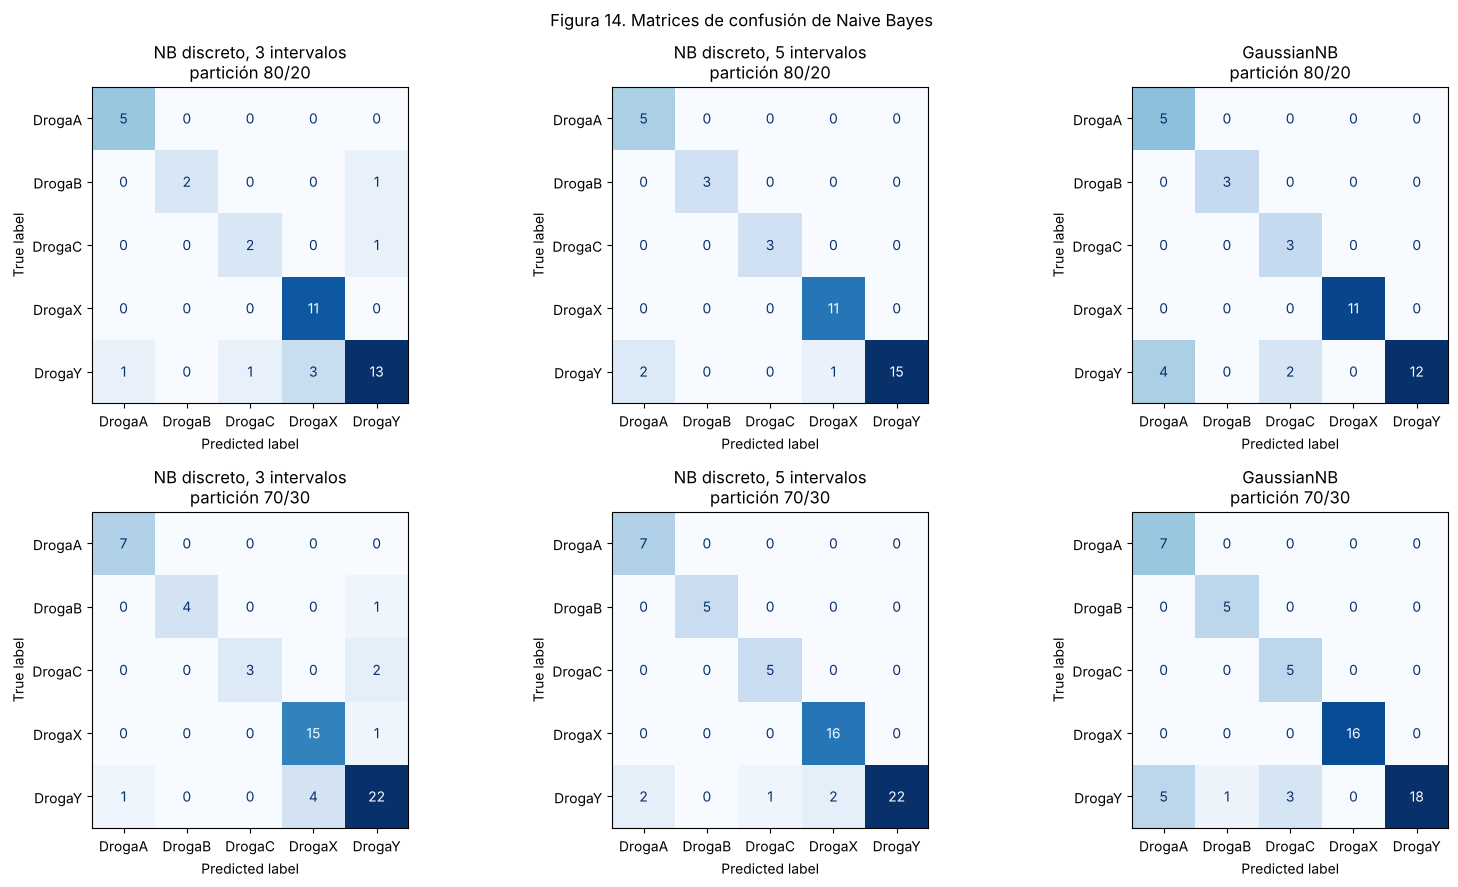

In [27]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for fila, nombre in zip(axes, part_B):
    for ax, etiqueta in zip(fila, ["NB discreto, 3 intervalos", "NB discreto, 5 intervalos", "GaussianNB"]):
        ConfusionMatrixDisplay.from_predictions(part_B[nombre][3], preds_B[(etiqueta, nombre)], ax=ax,
                                                cmap="Blues", colorbar=False)
        ax.set_title(f"{etiqueta}\npartición {nombre}")
plt.suptitle("Figura 14. Matrices de confusión de Naive Bayes")
plt.tight_layout()
plt.show()

Bordes de los 5 intervalos en la partición 80/20: Edad [15, 28, 39, 50, 61.5, 74] y Na_a_K [6.3, 9.9, 12.8, 16.1, 22.8, 38.2]. El intervalo de Na_a_K entre 12.8 y 16.1 mezcla casos de DrogaY (desde 15.02) con casos de las otras clases (hasta 14.64). El corte exacto que usó el árbol (14.829) no existe en esta discretización.

Resultados (F1 macro de validación sobre train, y métricas sobre test):

- 3 intervalos: F1 de validación 0.691 (80/20) y 0.639 (70/30). Accuracy de test 0.825 y 0.850.
- 5 intervalos: F1 de validación 0.811 y 0.766. Accuracy de test 0.925 y 0.917. Recall macro 0.967 y 0.963.
- GaussianNB: F1 de validación 0.813 y 0.843. Accuracy de test 0.850 en ambas particiones. Precision macro 0.831 y 0.808.

Pasar de 3 a 5 intervalos mejora el F1 de validación de 0.691 a 0.811 y de 0.639 a 0.766, como esperábamos. GaussianNB queda primero en la validación cruzada de las dos particiones. En el 80/20 su ventaja sobre 5 intervalos es mínima (0.813 contra 0.811). En el 70/30 es mayor (0.843 contra 0.766). Por eso la hipótesis sobre GaussianNB se cumple solo en parte: en la validación rinde igual o mejor que 5 intervalos, y en test rinde peor en Accuracy (0.850 contra 0.925 y 0.917).

Decisión: elegimos GaussianNB como mejor Bayes Ingenuo, porque seleccionar con los resultados de test no corresponde. La tabla muestra las tres variantes completas.

Figura 14. Los errores se concentran en DrogaY. Con GaussianNB, 6 de 18 casos de DrogaY se clasifican mal en el 80/20 (4 como DrogaA y 2 como DrogaC) y 9 de 27 en el 70/30. Con 5 intervalos los errores de DrogaY bajan a 3 en el 80/20 y 5 en el 70/30. Con GaussianNB y con 5 intervalos, las otras cuatro clases no tienen errores propios. Con 3 intervalos también fallan DrogaB y DrogaC.

## Actividad 6. k-NN

Consigna: estimar Droga con KNeighborsClassifier, explorando n_neighbors (al menos 5 valores) y metric (euclidean, manhattan). Reportar Precision y Recall macro, Accuracy y la matriz de confusión en ambos test.

Partimos de la búsqueda de clase (KNN c38 a c41), con validación cruzada de 5 folds sobre train y F1 macro. La grilla tiene n_neighbors en 1, 3, 5, 7 y 9, y metric en euclidean y manhattan (10 combinaciones). Usamos los datos estandarizados, para que Edad y Na_a_K pesen parecido en la distancia (KNN c30). La clase más chica tiene 13 casos en el train del 80/20 y 11 en el del 70/30, y el k máximo (9) queda por debajo (KNN c34).

Hipótesis previa: k-NN separará bien a DrogaY por Na_a_K, pero la distancia trata BP y Colesterol como números ordinales. Esperamos un resultado por debajo del árbol.

Partición 80/20: mejor = {'metric': 'manhattan', 'n_neighbors': 1}, F1 macro CV = 0.874, clase más chica en train = 13


Partición 70/30: mejor = {'metric': 'manhattan', 'n_neighbors': 9}, F1 macro CV = 0.818, clase más chica en train = 11


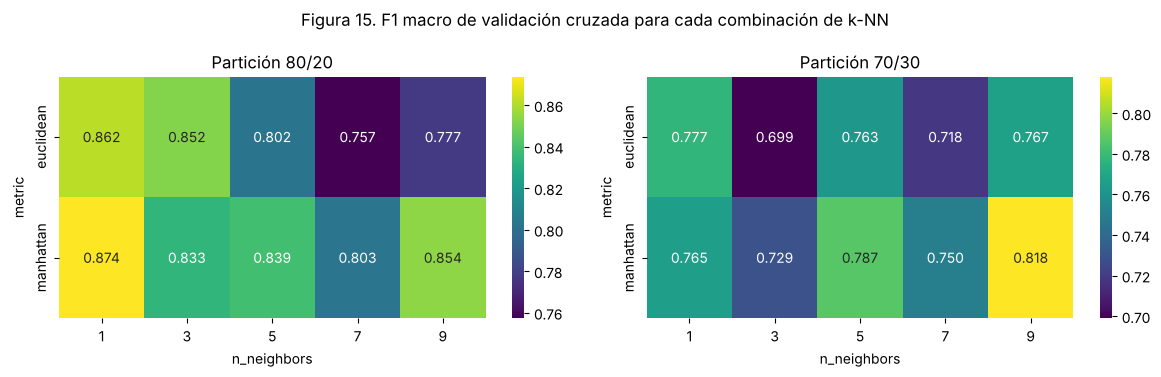

In [28]:
# Adaptado de U5_KNNClassifier.ipynb, celdas 38-41 (GridSearchCV de k-NN sobre datos estandarizados)
# El notebook varía p; el TP pide metric: euclidean o manhattan (U5 p.27 muestra el parámetro metric)
# ⚠️ REVISAR: scoring="f1_macro" (el notebook usa accuracy)
param_grid_knn = {"n_neighbors": [1, 3, 5, 7, 9], "metric": ["euclidean", "manhattan"]}
grids_knn = {}
for nombre in part_B:
    Xtr_s, Xte_s = datos_B[nombre]["std"]
    ytr, yte = part_B[nombre][2], part_B[nombre][3]
    grids_knn[nombre] = GridSearchCV(KNeighborsClassifier(), param_grid_knn, cv=5, scoring="f1_macro").fit(Xtr_s, ytr)
    g = grids_knn[nombre]
    preds_B[("k-NN", nombre)] = g.predict(Xte_s)
    met_B[("k-NN", nombre)] = metricas(yte, preds_B[("k-NN", nombre)])
    print(f"Partición {nombre}: mejor = {g.best_params_}, F1 macro CV = {g.best_score_:.3f}, "
          f"clase más chica en train = {ytr.value_counts().min()}")

# ⚠️ REVISAR: tabla dinámica de cv_results_ para el heatmap (no está en el material)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (nombre, g) in zip(axes, grids_knn.items()):
    r = pd.DataFrame(g.cv_results_)
    sns.heatmap(r.pivot(index="param_metric", columns="param_n_neighbors", values="mean_test_score").astype(float),
                annot=True, fmt=".3f", cmap="viridis", ax=ax)
    ax.set_title(f"Partición {nombre}")
    ax.set_xlabel("n_neighbors")
    ax.set_ylabel("metric")
plt.suptitle("Figura 15. F1 macro de validación cruzada para cada combinación de k-NN")
plt.tight_layout()
plt.show()

Precision macro  Recall macro  Accuracy
Modelo Partición                                         
k-NN   80/20                0.870         0.937     0.875
       70/30                0.935         0.930     0.917

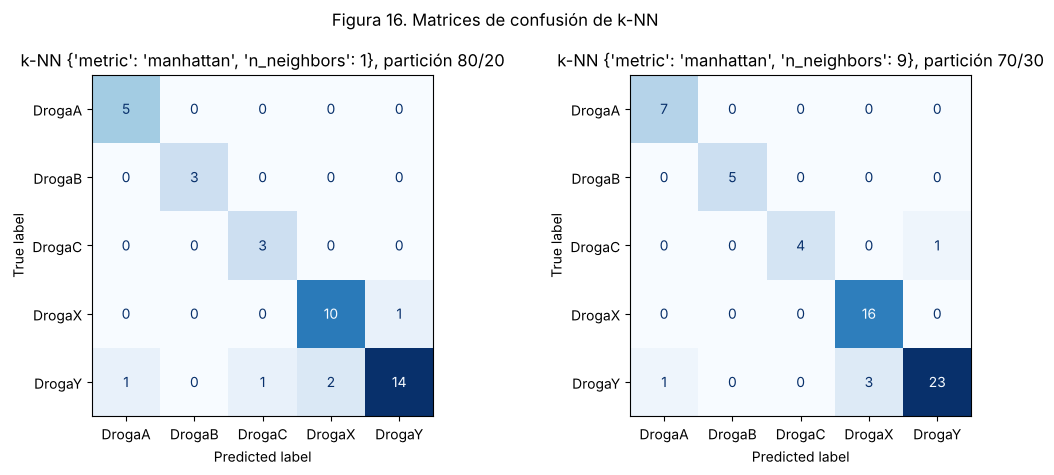

In [29]:
display(pd.DataFrame({k: v for k, v in met_B.items() if k[0] == "k-NN"}).T.rename_axis(["Modelo", "Partición"]).round(3))
plot_cms([(part_B[n][3], preds_B[("k-NN", n)], f"k-NN {grids_knn[n].best_params_}, partición {n}") for n in part_B],
         "Figura 16. Matrices de confusión de k-NN")

Figura 15. La mejor combinación es manhattan con k=1 en el 80/20 (F1 de validación 0.874) y manhattan con k=9 en el 70/30 (0.818). Manhattan supera a euclidean en 4 de los 5 valores de k en cada partición. El F1 no sigue una tendencia clara con k: en el 80/20 el máximo está en k=1 y en el 70/30 en k=9. Con 140 a 160 observaciones de train, la elección de k depende de la partición.

Resultados sobre test: en el 80/20, Precision macro 0.870, Recall macro 0.937 y Accuracy 0.875. En el 70/30, 0.935, 0.930 y 0.917.

Figura 16. Los errores del 80/20 son DrogaY clasificada como DrogaX (2 casos), DrogaA (1) y DrogaC (1), y un DrogaX clasificado como DrogaY. En el 70/30 son DrogaY como DrogaX (3) y DrogaA (1), y un DrogaC como DrogaY. DrogaA y DrogaB no tienen errores de Recall en ninguna partición. La hipótesis se cumple: k-NN queda por debajo del árbol (Accuracy 0.875 y 0.917 contra 1.0).

## Actividad 7. Comparación de modelos

Consigna: comparar el mejor modelo de cada algoritmo (árbol de decisión, Bayes Ingenuo y k-NN) sobre ambos test, y elegir y justificar el más adecuado según las métricas y la interpretabilidad.

La tabla reúne el árbol podado (igual al no podado, ver Actividad 4), el Bayes Ingenuo elegido por validación cruzada (GaussianNB) y el k-NN de la Actividad 6.

In [30]:
# Tabla comparativa (patrón de U5_BayesClassifier.ipynb, celda 48): mejor modelo de cada algoritmo
final = []
for nombre in part_B:
    for algoritmo, clave in [("Árbol de decisión (podado)", "Árbol podado"),
                             (f"Bayes Ingenuo ({mejor_nb[nombre]})", mejor_nb[nombre]),
                             ("k-NN", "k-NN")]:
        final.append({"Partición": nombre, "Algoritmo": algoritmo, **met_B[(clave, nombre)]})
comparacion = pd.DataFrame(final).set_index(["Partición", "Algoritmo"])
display(comparacion.round(3))

Precision macro  Recall macro  Accuracy
Partición Algoritmo                                                          
80/20     Árbol de decisión (podado)            1.000         1.000     1.000
          Bayes Ingenuo (GaussianNB)            0.831         0.933     0.850
          k-NN                                  0.870         0.937     0.875
70/30     Árbol de decisión (podado)            1.000         1.000     1.000
          Bayes Ingenuo (GaussianNB)            0.808         0.933     0.850
          k-NN                                  0.935         0.930     0.917

Resultados (Precision macro, Recall macro y Accuracy):

- Árbol de decisión: 1.000, 1.000 y 1.000 en ambos test.
- k-NN: 0.870, 0.937 y 0.875 en el 80/20, y 0.935, 0.930 y 0.917 en el 70/30.
- Bayes Ingenuo (GaussianNB): 0.831, 0.933 y 0.850 en el 80/20, y 0.808, 0.933 y 0.850 en el 70/30.

Elegimos el árbol de decisión por estas razones:

- Tiene las mejores métricas en ambos test y es el único modelo sin errores en las matrices de confusión.
- Es interpretable: sus 6 reglas usan 4 atributos (Na_a_K, BP, Colesterol y Edad) y se leen directamente en las Figuras 11 y 12. Coinciden con lo que mostró el EDA (U4 p.2).
- k-NN no entrega reglas que expliquen cada predicción (U5 p.17) y su F1 de validación (0.874 y 0.818) es menor que el del árbol (0.977 y 0.965).
- Bayes Ingenuo es simple y rápido (U5 p.12), pero queda por debajo del árbol en las tres métricas.

Limitaciones: los test tienen 40 y 60 observaciones, con 3 a 5 casos en las clases chicas, por lo que un 1.0 no garantiza el mismo resultado con datos nuevos. Los árboles de las dos particiones usan el mismo umbral de Na_a_K (14.829) y las mismas variables, lo que sugiere reglas estables.

# Conclusiones

Parte A (regresión):

- Eliminamos 3 filas anómalas de Profit y una fila duplicada. Con la misma configuración, el RMSE de test baja de 19313.7 a 3496.1 en el 80/20 y de 15805.7 a 2929.1 en el 70/30. La comparación es aproximada porque los test difieren en algunas filas.
- El mejor árbol (max_depth=10, min_samples_leaf=5 y min_samples_split=2) logra MAE de 1098.9 y 942.6, y RMSE de 3496.1 y 2929.1 en los test 80/20 y 70/30.
- RyD_Spend domina los primeros cortes, en coincidencia con su correlación de 0.999 con Profit. Administration tiene correlación moderada (0.745) y casi no interviene en el árbol.
- Tres filas explican cerca de dos tercios del error cuadrático en ambos test. Esas filas están entre las primeras 50 del archivo y quedan fuera de la recta de la Figura 4.

Parte B (clasificación):

- Droga está desbalanceada (la clase mayoritaria es 5.69 veces la minoritaria). Estratificamos las particiones y usamos métricas macro.
- Na_a_K separa a DrogaY. BP, Colesterol y Edad separan las demás clases. El árbol de 6 hojas lo refleja y alcanza 1.000 en Precision macro, Recall macro y Accuracy en ambos test.
- La validación cruzada eligió ccp_alpha=0.0. La poda por complejidad bajó el F1 de validación en todos los valores positivos, y el árbol antes y después de podar es el mismo.
- En Bayes Ingenuo, 5 intervalos rinden mejor que 3. GaussianNB ganó la validación cruzada y alcanzó Accuracy de 0.850 en ambos test. Con 5 intervalos el Accuracy de test fue 0.925 y 0.917.
- k-NN con distancia manhattan alcanzó Accuracy de 0.875 (k=1) y 0.917 (k=9). La elección de k cambió con la partición.
- Elegimos el árbol de decisión por sus métricas y por la claridad de sus reglas.

Puntos a tener en cuenta: los test son chicos y la selección de hiperparámetros se apoya en validación cruzada sobre train, con una sola semilla (63). Con más datos conviene repetir la comparación.